# 02 – Exploration: does the data support our story?

Before making final figures we test every claim from the proposal against `data/clean/fires.parquet`. Plots here are
**quick drafts** for checking, not report figures.

## Summary of findings

| Q | Proposal claim | Verdict | Evidence |
|---|---|---|---|
| Q1 | Area burned is increasing | **Partly** | Rising over 1959–2025 (Spearman ρ = 0.50, p < 0.001), but **no significant trend 1980–2022** (ρ = 0.07, p = 0.65). The rise comes from low 1960s–70s totals (partly weaker northern monitoring) and the **2023–2025 cluster**: three of the seven largest years on record. |
| Q1 | 2023 was unusual | **Strongly yes** | 17.6 Mha: **2.3×** the previous record (1989, 7.6 Mha) and **11×** a median year. May 2023 alone (6.45 Mha) burned more than any full year except 1989 and 1995. |
| Q1 | Number of fires is falling | **Yes, since 1989** | Peak of 12,015 fires in 1989; 9,300/yr in 1985–89 vs 6,200/yr in 2021–25 (1980–2025 ρ = −0.63, p < 0.001). The fall is in **human-caused** fires. The rise before 1989 is mostly better reporting. |
| Q1 | (heat map) Fire season starting earlier | **Not supported** | Median start of large fires moved slightly *later* (day 180 → 190). Use the heat map to show **when area burns** and how extreme May–July 2023 was, not an earlier season. |
| Q2 | Lightning: under half of fires, most of the area | **Strongly yes** | Lightning: 44% of fires, **85% of area**. Human: 53% of fires, **10% of area**. In 2023 lightning was 92% of area. |
| Q2 | Causes differ by season | **Yes** | Human fires peak in spring (April–May = 41%, after snowmelt, before green-up); lightning fires peak in July and 90% fall in June–August. |
| Q2 | Causes differ by place | **Yes** | 48% of human fires are south of 50° N vs 24% of lightning fires. NT: 96% of area is lightning; NB/NS: human-dominated but tiny area. |
| Q2 | Causes differ by size | **Yes** | 8.6% of lightning fires reach 200 ha vs 1.6% of human fires; median large lightning fire 1,500 ha vs 600 ha. |
| Q3 | A few huge fires burn most of the area | **Strongly yes** | **0.2% of fires (742) = half of all area; top 1% = 83%.** Largest: 1.05 Mha (NT, 1995, lightning). |
| Q3 | Typical fire size changed by decade | **Yes, for large fires** | Median large fire 782 ha (1960s) → 1,617 ha (2020s); share ≥ 10,000 ha 8% → 20%. Use `is_large` only. |
| Q4 | Main hotspots | **Yes, once normalised** | Per 1,000 km²: SK, MB, NT, AB lead, a west-central boreal belt. Raw totals would wrongly put NT first. |
| Q4 | Hotspots shifted over time | **Weakly** | No clear northward shift. **BC's share of area rose** from 1–6% (1970s–2000s) to 13–16% (2010s–2020s); NT dominated in the 1970s and 1990s. Frame as "shifting west", with care. |

### Changes to make in the report
1. **Q1 wording:** "Is area burned increasing?" → the honest answer is *"high year-to-year variability with no clear trend
   from 1980 to 2022, followed by three extreme years"*. That is a stronger, more interesting story than a steady rise.
2. **Drop the "season starting earlier" idea** for the heat map; use it to show where 2023 sits.
3. **Q4:** use small multiples by decade and province share of area; say plainly that the shift is modest.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fires = pd.read_parquet("../data/clean/fires.parquet")
provinces = pd.read_parquet("../data/clean/provinces.parquet", columns=["province", "land_km2"])
rng = np.random.default_rng(0)


def trend(years, values, n_perm=2000):
    """Theil–Sen slope, Spearman rho and a permutation p-value (two-sided)."""
    x = np.asarray(years, float)
    y = np.asarray(values, float)
    i, j = np.triu_indices(len(x), k=1)
    slope = np.median((y[j] - y[i]) / (x[j] - x[i]))
    x_rank = pd.Series(x).rank()
    rho = x_rank.corr(pd.Series(y).rank())
    perm = np.array([x_rank.corr(pd.Series(rng.permutation(y)).rank()) for _ in range(n_perm)])
    return pd.Series({"slope": slope, "rho": rho, "p": (np.abs(perm) >= abs(rho)).mean()})


annual = fires.groupby("year").agg(fires=("size_ha", "size"), area_ha=("size_ha", "sum"),
                                   large_fires=("is_large", "sum"))

## Q1 – Is area burned increasing, and how unusual was 2023?

Area is tested on a log scale because yearly totals vary by more than 10×. We test three windows: the full record, from
1980 (when northern monitoring was more complete), and 1980–2022 (to see the trend without the recent extreme years).

In [2]:
windows = {"1959–2025": (1959, 2025), "1980–2025": (1980, 2025), "1980–2022": (1980, 2022)}
rows = []
for label, (start, end) in windows.items():
    a = annual.loc[start:end]
    rows.append(trend(a.index, np.log10(a["area_ha"])).add_prefix("log area ")
                .combine_first(trend(a.index, a["fires"]).add_prefix("fires ")).rename(label))
pd.DataFrame(rows).round(3)

,fires p,fires rho,fires slope,log area p,log area rho,log area slope
1959–2025,0.02,0.285,38.774,0.000,0.499,0.011
1980–2025,0.00,-0.629,-80.000,0.134,0.226,0.008
1980–2022,0.00,-0.619,-91.581,0.648,0.074,0.003


2023: 17.6 Mha = 2.3x the previous record (1989) and 11x the median year
Ten largest years (Mha): {2023: 17.6, 2025: 8.7, 1989: 7.6, 1995: 7.5, 1981: 6.3, 1994: 6.2, 2024: 5.4, 1980: 4.8, 1998: 4.8, 2014: 4.5}
Fire count peak: 1989 (12,015); 1985–89 mean 9,300 vs 2021–25 mean 6,201


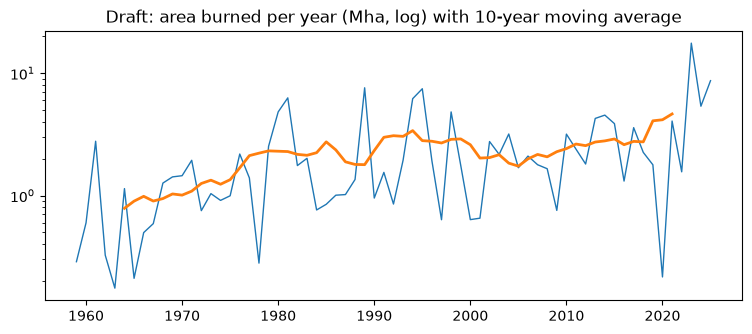

In [3]:
before = annual.loc[:2022, "area_ha"]
print(f"2023: {annual.loc[2023, 'area_ha'] / 1e6:.1f} Mha = {annual.loc[2023, 'area_ha'] / before.max():.1f}x the previous "
      f"record ({before.idxmax()}) and {annual.loc[2023, 'area_ha'] / before.median():.0f}x the median year")
print("Ten largest years (Mha):", (annual["area_ha"].nlargest(10) / 1e6).round(1).to_dict())
print(f"Fire count peak: {annual['fires'].idxmax()} ({annual['fires'].max():,}); "
      f"1985–89 mean {annual.loc[1985:1989, 'fires'].mean():,.0f} vs 2021–25 mean {annual.loc[2021:2025, 'fires'].mean():,.0f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(annual.index, annual["area_ha"] / 1e6, lw=1)
ax.plot(annual.index, annual["area_ha"].rolling(10, center=True).mean() / 1e6, lw=2)
ax.set_yscale("log")
ax.set(title="Draft: area burned per year (Mha, log) with 10-year moving average", xlabel="")
plt.show()

Largest single months (Mha): {(2023, 5): 6.45, (2023, 7): 5.02, (1995, 6): 4.96, (2023, 6): 4.79, (1989, 7): 4.71}
May 2023 alone beats every full year except: [1989, 1995]
Median start day of large fires by decade: {'1950s': 177.0, '1960s': 180.0, '1970s': 185.0, '1980s': 187.0, '1990s': 179.0, '2000s': 183.0, '2010s': 187.0, '2020s': 190.0}


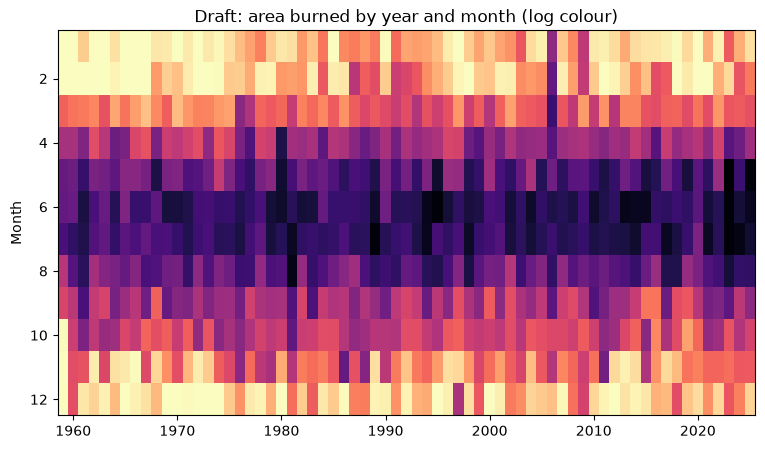

In [4]:
monthly = (fires.dropna(subset=["month"]).groupby(["year", "month"])["size_ha"].sum()
           .unstack(fill_value=0))
print("Largest single months (Mha):", (monthly.stack().nlargest(5) / 1e6).round(2).to_dict())
may_2023 = monthly.loc[2023, 5]
print("May 2023 alone beats every full year except:",
      before[before > may_2023].index.tolist())

large = fires[fires["is_large"] & fires["doy"].notna()]
print("Median start day of large fires by decade:", large.groupby("decade")["doy"].median().to_dict())

fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(np.log10(monthly.T + 1), aspect="auto", cmap="magma_r",
          extent=[monthly.index.min() - 0.5, monthly.index.max() + 0.5, 12.5, 0.5])
ax.set(title="Draft: area burned by year and month (log colour)", ylabel="Month")
plt.show()

## Q2 – How do lightning and human fires differ?

In [5]:
by_cause = fires.groupby("cause", observed=True).agg(
    fires=("size_ha", "size"), area_ha=("size_ha", "sum"), share_large=("is_large", "mean"),
    median_lat=("lat", "median"), median_doy=("doy", "median"))
by_cause["% of fires"] = by_cause["fires"] / by_cause["fires"].sum() * 100
by_cause["% of area"] = by_cause["area_ha"] / by_cause["area_ha"].sum() * 100
by_cause["% south of 50N"] = fires.groupby("cause", observed=True)["lat"].apply(lambda s: (s < 50).mean() * 100)
by_cause["median large-fire ha"] = fires[fires["is_large"]].groupby("cause", observed=True)["size_ha"].median()
by_cause.round(2)

,fires,area_ha,share_large,median_lat,median_doy,% of fires,% of area,% south of 50N,median large-fire ha
cause,,,,,,,,,
Human,231160,1.686809e+07,0.02,50.20,166.0,53.44,10.40,47.55,600.0
Lightning,190632,1.385168e+08,0.09,52.32,200.0,44.07,85.41,23.98,1499.5
Unknown,10803,6.794572e+06,0.08,51.66,159.0,2.50,4.19,42.53,1348.9


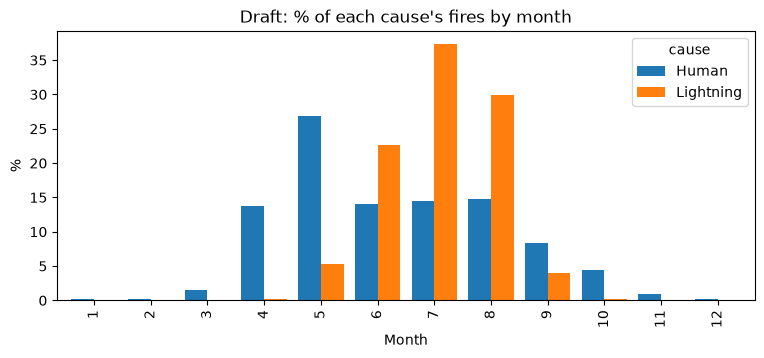

In [6]:
month_share = fires.groupby(["month", "cause"], observed=True).size().unstack()
month_share = month_share / month_share.sum() * 100

fig, ax = plt.subplots(figsize=(9, 3.5))
month_share[["Human", "Lightning"]].plot.bar(ax=ax, width=0.8)
ax.set(title="Draft: % of each cause's fires by month", xlabel="Month", ylabel="%")
plt.show()

In [7]:
per_prov = fires.groupby(["province", "cause"], observed=True)["size_ha"].agg(["size", "sum"]).unstack()
pd.DataFrame({
    "area Mha": per_prov["sum"].sum(axis=1) / 1e6,
    "lightning % of fires": per_prov["size"]["Lightning"] / per_prov["size"].sum(axis=1) * 100,
    "lightning % of area": per_prov["sum"]["Lightning"] / per_prov["sum"].sum(axis=1) * 100,
}).sort_values("area Mha", ascending=False).round(1)

,area Mha,lightning % of fires,lightning % of area
province,,,
NT,37.6,78.7,96.1
SK,30.2,47.4,85.1
MB,20.1,44.4,73.7
QC,19.0,28.1,89.9
AB,17.6,43.8,73.9
BC,14.0,49.7,81.1
ON,11.6,48.0,84.2
YT,9.6,55.5,91.0
NL,2.1,11.9,80.3


## Q3 – Do a few huge fires burn most of the area?

The cumulative share (Lorenz) curve answers this directly: sort fires from largest to smallest and add up their area.

Largest 0.1% of fires (392) burned 38.5% of the area
Largest 1.0% of fires (3,926) burned 82.9% of the area
Largest 5.0% of fires (19,632) burned 98.8% of the area
Half of all area came from 742 of 392,647 fires


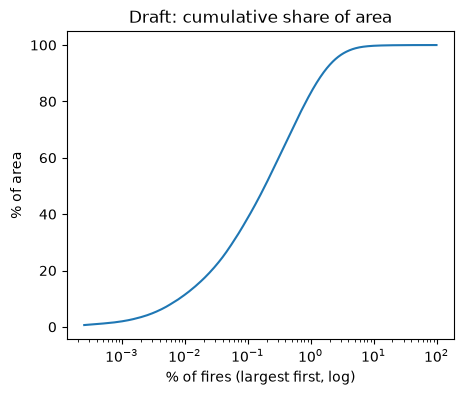

In [8]:
sizes = np.sort(fires.loc[fires["has_size"], "size_ha"].to_numpy())[::-1]
cum_share = sizes.cumsum() / sizes.sum()
n = len(sizes)
for q in [0.001, 0.01, 0.05]:
    print(f"Largest {q:.1%} of fires ({int(q * n):,}) burned {cum_share[int(q * n) - 1]:.1%} of the area")
print(f"Half of all area came from {np.searchsorted(cum_share, 0.5) + 1:,} of {n:,} fires")

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(np.arange(1, n + 1) / n * 100, cum_share * 100)
ax.set_xscale("log")
ax.set(title="Draft: cumulative share of area", xlabel="% of fires (largest first, log)", ylabel="% of area")
plt.show()

In [9]:
large_fires = fires[fires["is_large"]]
decade_size = large_fires.groupby("decade")["size_ha"].agg(
    fires="size", median="median", p90=lambda s: s.quantile(0.9), share_10k=lambda s: (s >= 10_000).mean() * 100)
print(trend(*zip(*large_fires.groupby("year")["size_ha"].median().pipe(np.log10).items()))
      .round(4).rename("trend in log median large-fire size").to_dict())
decade_size.round(1)

{'slope': 0.0048, 'rho': 0.5318, 'p': 0.0}


,fires,median,p90,share_10k
decade,,,,
1950s,161,600.0,3440.0,3.7
1960s,2088,781.7,8317.2,8.1
1970s,2415,1036.0,11977.9,11.8
1980s,3389,1135.5,15977.4,15.0
1990s,3198,1476.0,18307.8,17.4
2000s,2919,1257.1,13239.6,13.5
2010s,3548,1389.0,15338.4,14.7
2020s,3099,1617.0,24163.2,20.4


## Q4 – Where are the hotspots, and have they shifted?

Raw totals favour the largest provinces, so we normalise by land area and by the 67 years of record.

In [10]:
hotspots = fires.groupby("province")["size_ha"].sum().to_frame("area_ha").join(provinces.set_index("province"))
hotspots["ha per 1,000 km² per year"] = hotspots["area_ha"] / hotspots["land_km2"] * 1000 / annual.index.nunique()
hotspots["% of national area"] = hotspots["area_ha"] / hotspots["area_ha"].sum() * 100
hotspots.sort_values("ha per 1,000 km² per year", ascending=False).round(1)

,area_ha,land_km2,"ha per 1,000 km² per year",% of national area
province,,,,
SK,30249095.5,577060.4,782.4,18.7
MB,20101925.0,540310.2,555.3,12.4
NT,37565324.0,1127711.9,497.2,23.2
AB,17556013.4,634658.3,412.9,10.8
YT,9581931.4,472345.4,302.8,5.9
BC,13962595.7,920686.6,226.3,8.6
QC,19021785.0,1298599.7,218.6,11.7
ON,11640548.0,892411.8,194.7,7.2
NL,2077547.4,358170.4,86.6,1.3


In [11]:
decade_prov = fires.groupby(["decade", "province"])["size_ha"].sum().unstack(fill_value=0)
decade_share = decade_prov.div(decade_prov.sum(axis=1), axis=0) * 100

centre = large_fires.dropna(subset=["lat"]).groupby("decade").apply(
    lambda d: pd.Series({"lat": np.average(d["lat"], weights=d["size_ha"]),
                         "lon": np.average(d["lon"], weights=d["size_ha"])}), include_groups=False)
display(decade_share[["BC", "AB", "SK", "MB", "NT", "YT", "ON", "QC"]].round(0))
centre.round(2).rename(columns={"lat": "area-weighted lat", "lon": "area-weighted lon"})

province,BC,AB,SK,MB,NT,YT,ON,QC
decade,,,,,,,,
1950s,38.0,10.0,4.0,3.0,14.0,14.0,0.0,12.0
1960s,12.0,8.0,10.0,20.0,17.0,12.0,6.0,11.0
1970s,5.0,5.0,17.0,6.0,37.0,6.0,12.0,8.0
1980s,4.0,13.0,19.0,20.0,16.0,4.0,8.0,15.0
1990s,1.0,5.0,17.0,13.0,34.0,6.0,10.0,11.0
2000s,6.0,11.0,26.0,12.0,12.0,14.0,4.0,15.0
2010s,13.0,15.0,19.0,8.0,25.0,5.0,6.0,9.0
2020s,16.0,13.0,19.0,11.0,21.0,3.0,5.0,13.0


,area-weighted lat,area-weighted lon
decade,,
1950s,57.44,-112.53
1960s,56.35,-105.88
1970s,58.29,-105.59
1980s,56.64,-102.98
1990s,58.30,-106.04
2000s,57.38,-106.19
2010s,57.63,-108.96
2020s,56.88,-107.44
